import the necessary libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import logging
from matplotlib.colors import LinearSegmentedColormap, BoundaryNorm

I used logs so that I could track code execution and handle errors more efficiently.

In [2]:
try:
    log = logging.getLogger(__name__)
    log.setLevel(logging.INFO)
    if log.handlers:
        log.handlers.clear()
    handler = logging.StreamHandler()
    handler.setFormatter(logging.Formatter('%(asctime)s - %(name)s - %(levelname)s - %(message)s', datefmt='%d-%b-%y %H:%M:%S'))
    log.addHandler(handler)
    log.propagate = False
except  ImportError:
    print ("Logging module not found, continuing without it")

Loading the dataset; This particular dataset is from the NASA exoplanet catalogue.

In [3]:
try:
    df = pd.read_csv("PlanetaryData.csv")
    log.info("Data has been loaded successfully")
except FileNotFoundError as e:
    log.error(f"File not found, confirm the file is in the same folder as the notebook: {e}")

21-Oct-26 09:26:11 - __main__ - INFO - Data has been loaded successfully


Description of the data, that is the shape, and the overall information of the data.

In [4]:
try:
    log.info(df.shape)
    log.info(df.info())
except Exception as e:
    log.error(f"An unexpected error has occurred: {e}")

21-Oct-26 09:26:11 - __main__ - INFO - (4575, 23)
21-Oct-26 09:26:11 - __main__ - INFO - None


<class 'pandas.DataFrame'>
RangeIndex: 4575 entries, 0 to 4574
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   No.                            4575 non-null   int64  
 1   Planet Name                    4575 non-null   str    
 2   Planet Host                    4575 non-null   str    
 3   Num Stars                      4575 non-null   int64  
 4   Num Planets                    4575 non-null   int64  
 5   Discovery Method               4575 non-null   str    
 6   Discovery Facility             4575 non-null   str    
 7   Orbital Period Days            4413 non-null   float64
 8   Orbit Semi-Major Axis          2763 non-null   float64
 9   Mass                           2006 non-null   float64
 10  Eccentricity                   1707 non-null   float64
 11  Insolation Flux                370 non-null    float64
 12  Equilibrium Temperature        925 non-null    float64
 13 

checking the magnitude of missing values / data in the dataset.

In [5]:
try:
    missing = df.isnull().sum()
    total  = len(df)
    missing_per = df.isnull().sum() / total * 100
    missing_df = pd.DataFrame({
        "missing": missing,
        "missing_percent(%)" : missing_per.round(1),
    })
    log.info(missing_df.sort_values(by="missing_percent(%)", ascending=False))
except Exception as e:
    log.error(f"An unexpected error has occurred: {e}")
    raise

21-Oct-26 09:26:11 - __main__ - INFO -                                missing  missing_percent(%)
Insolation Flux                   4205                91.9
Equilibrium Temperature           3650                79.8
Spectral Type                     3647                79.7
Eccentricity                      2868                62.7
Mass                              2569                56.2
Orbit Semi-Major Axis             1812                39.6
Stellar Metallicity Ratio         1383                30.2
Stellar Metallicity               1371                30.0
Stellar Mass                       731                16.0
Stellar Surface Gravity            603                13.2
Stellar Radius                     447                 9.8
Stellar Effective Temperature      349                 7.6
Gaia Magnitude                     175                 3.8
Orbital Period Days                162                 3.5
Distance                           104                 2.3
Discovery Facilit

The columns, insolation flux, equilibrium temperature and spectral type had too much missing data; trying to fill them using mean or median could distort the scientific relationships which were crucial. The goal was to visualize the relationships between variables and therefore dropping the columns missing too much data would be more reasonable. Columns that were not going to be used were dropped too.

In [6]:
try:
    dropped_columns = [
        "Insolation Flux", "Spectral Type", "Equilibrium Temperature", "Discovery Facility", "Gaia Magnitude"
    ]
    log.info(f"Shape before dropping columns: {df.shape}")
    clean_df = df.drop(columns=dropped_columns)
    log.info(f"Shape after dropping columns: {clean_df.shape}")
except KeyError as e:
    log.error(f"Column not found in dataframe: {e}")
    raise
except Exception as e:
    log.error(f"An unexpected error has occurred: {e}")
    raise

21-Oct-26 09:26:11 - __main__ - INFO - Shape before dropping columns: (4575, 23)
21-Oct-26 09:26:11 - __main__ - INFO - Shape after dropping columns: (4575, 18)


How was the distribution of planet discoveries? Astronomy is essentially as old as humanity itself; but when were the first planets discovered.

21-Oct-26 09:26:11 - __main__ - INFO - Working with 30 rows


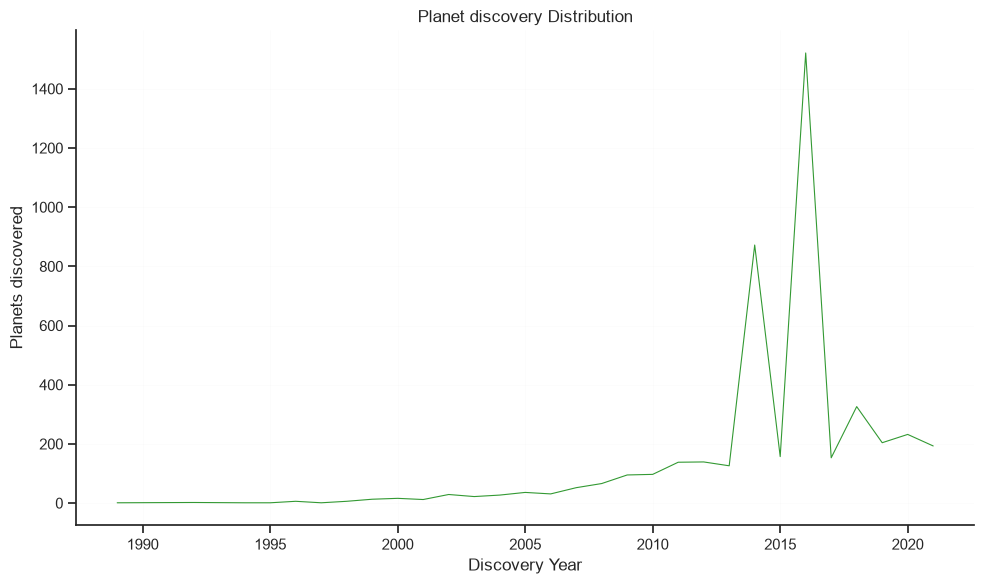

In [7]:
try:
    discovery_distribution = clean_df["Discovery Year"].value_counts().sort_index()
    log.info(f"Working with {len(discovery_distribution)} rows")
    sns.set_theme(style="ticks")
    fig, ax = plt.subplots(figsize=(10, 6))
    plot = sns.lineplot(
        x=discovery_distribution.index,
        y=discovery_distribution.values,
        color="green",
        alpha=0.8,
        linewidth=0.8,
        linestyle="-",
        ax=ax,
    )
    ax.set_xlabel("Discovery Year")
    ax.set_ylabel("Planets discovered")
    ax.set_title("Planet discovery Distribution")
    ax.grid(True, alpha=0.1, linewidth=0.4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.show()
except KeyError as e:
    log.error(f"Column not found in dataframe; check column names again: {e}")
    raise
except Exception as e:
    log.error(f"An unexpected error has occurred: {e}")
    raise

This particular dataset has planets that were recorded as early as 1995 and onwards. The biggest spike here is shown on the year 2016. This is a result of mass verifications of planets by the Kepler Space Telescope.  This haul included planets like Proxima Centauri; the closest exoplanet to the solar system. 2014 also had a numerous number of exoplanets discovered. The plot shows 800+ planets having been discovered in 2014. These were also found by the Kepler Space Telescope. Planets like kepler-186f which was within the habitable zone of it's star and kepler-10c dubbed as a mega-earth as it was way more massive than the sun were found in that year.

How does semi-major axis of a planet influence the time it takes to orbit the star?  A semi-major axis is a metric used to define the average distance between an orbiting body, and it's central star or planet.

21-Oct-26 09:26:11 - __main__ - INFO - Working with 1555 planets


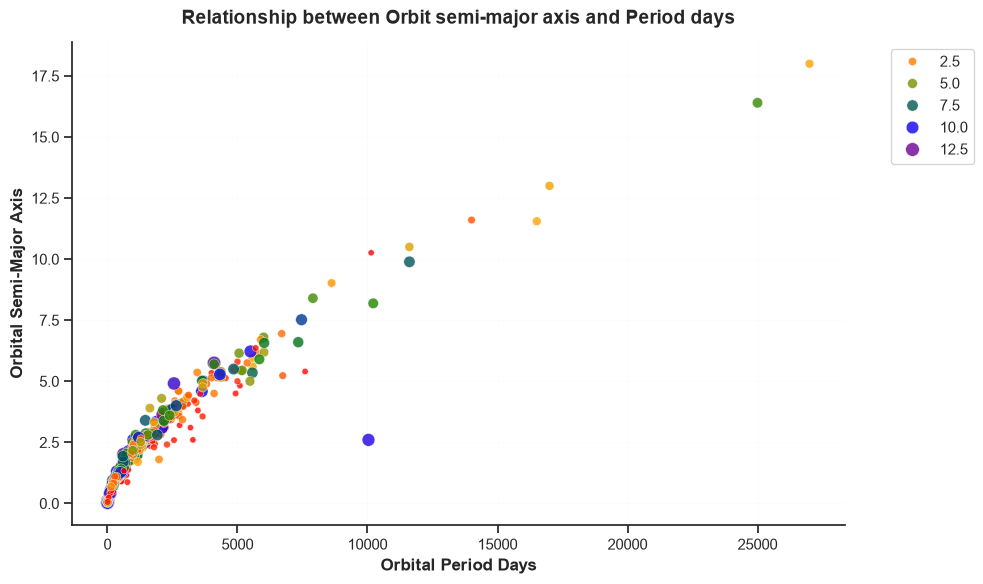

21-Oct-26 09:26:11 - __main__ - INFO - Correlation: 0.93


In [8]:
try:
    axis_days = clean_df[["Orbit Semi-Major Axis", "Orbital Period Days", "Mass"]].dropna()
    log.info(f"Working with {len(axis_days)} planets")
    axis_days["mass_jup"] = axis_days["Mass"] / 317.8  # create another column with converted earth masses to jupiter masses as most planets here are way more massive than earth
    axis_days = axis_days[axis_days["Orbit Semi-Major Axis"] < 20] # planets less than 20 AU to reduce the compactness of the scatter
    axis_days = axis_days[axis_days["mass_jup"] < 13] #filter bodies bigger than 13 jupiter masses as that is widely regarded as brown dwarfs territory
    colors = ["red", "orange", "green", "blue", "purple"] #List of colors used for the scatters
    bounds = [2, 4, 6, 8, 10, 12] # represents the masses of planets (jupiter masses) in which the colors wil be blended within. Each value represents a threshold for a certain color
    custom_colors = LinearSegmentedColormap.from_list("custom_colors", colors)
    norm = BoundaryNorm(bounds, custom_colors.N)
    sns.set_theme(style="ticks")
    fig, ax = plt.subplots(figsize=(10, 6))
    scatter = sns.scatterplot(
        x= "Orbital Period Days",
        y = "Orbit Semi-Major Axis",
        data=axis_days,
        hue = "mass_jup",
        size = "mass_jup",
        palette = custom_colors,
        sizes = (20, 100),
        alpha = 0.8,
        ax=ax
    )
    ax.set_xlabel("Orbital Period Days", fontsize=12, fontweight="bold")
    ax.set_ylabel("Orbital Semi-Major Axis", fontsize=12, fontweight="bold")
    ax.set_title("Relationship between Orbit semi-major axis and Period days", fontsize=14, fontweight="bold", y=1.02)
    ax.grid(True, alpha=0.1, linewidth=0.4)
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.show()
    slope, intercept, r_value, p_value, std_err = stats.linregress(axis_days["Orbit Semi-Major Axis"], axis_days["Orbital Period Days"])
    log.info(f"Correlation: {r_value:.2f}")
except KeyError as e:
    log.error(f"Column not found in dataframe; check column names again: {e}")
    raise
except Exception as e:
    log.error(f"An unexpected error has occurred: {e}")

The plot shows a positive slope and the correlation value is a 0.93, which indicates a strong positive. The farther away a planet is from it ' s parent star, the longer the planet will take to orbit the star. This means that as Orbit Semi-major axis increases, the orbital period of that particular planet increases too. The period in which a planet takes to orbit a star is also dependent on the mass of the star apart from it ' s distance from the star. A more massive star will have a bigger gravitational acceleration and this means that the planet will orbit faster compared to a planet at the same distance from it ' s star but the star is less massive.
A question that might arise is whether the planet' s mass matters. A planet' s mass is basically negligible as compared to a star' s mass. Therefore, the mass of the star will completely overshadow the mass of the planet; An asteroid and a planet at the same distance from the star would essentially have the same orbital period. However, if it was a gas giant orbiting a brown dwarf, then the planet's mass becomes relevant. Brown dwarfs are typically failed stars with masses approximated to be 13 Jupiter masses up to 80 Jupiter masses. When two bodies are of comparable masses, none orbits the other; they both orbit their shared mass center which is known as the barycenter, the distance between the two bodies decides how fast they complete a single orbital loop.
A good example of how stellar mass affects the orbital period of a planet in the dataset is a planet named v Ophiuchi or nu Oph c. This planet (debated to be a brown dwarf as it is extremely heavy with roughly 21 - 24 Jupiter masses which is well within brown dwarf' s territory) is roughly 5.9 Astronomical Units from it ' s parent star and has an orbital period of roughly 8.7 years. Comparing this to Jupiter in our solar system; Jupiter is roughly 5.2 Astronomical Units from the sun and takes about 11.9 years to make a complete orbit around the sun. Therefore, V Ophiuchi sits further from it ' s star but takes less to orbit. This essentially comes down to how massive the parent star is.  The star V Oph is estimated to be 1.5 - 3 times more massive than the sun and this explains the Orbital period of it ' s planet.
Therefore, we can conclude from the dataset that the distnace of a planet from it ' s host star influences heavily how long it takes to complete a full orbit, with mass of the star being a considerable factor too.

How did the distribution detected exoplanets vary across different stellar system architectures and detection methods?

21-Oct-26 09:26:11 - __main__ - INFO - Working with 4575 planets


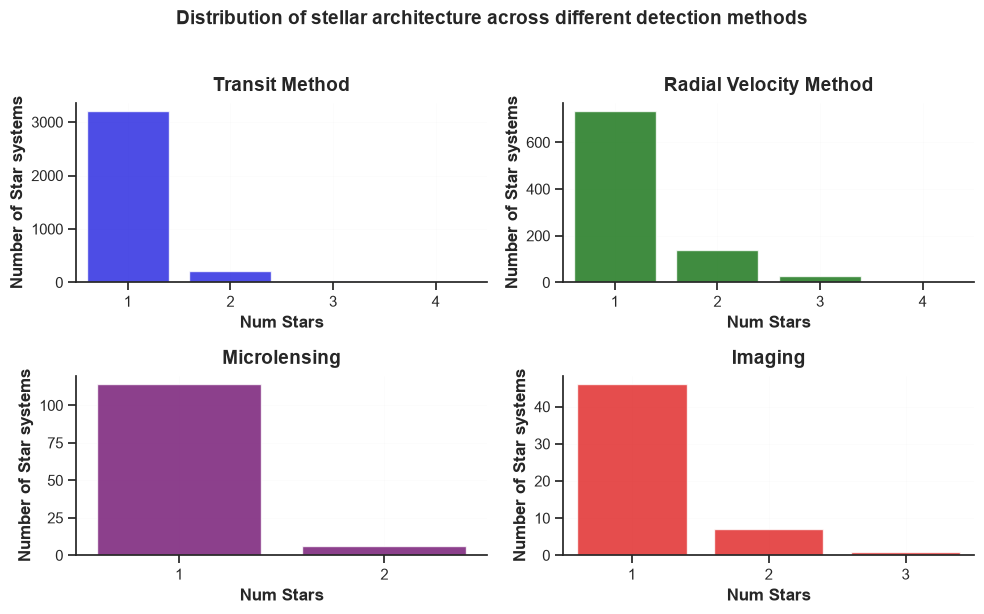

In [9]:
try:
    planet_distribution = clean_df[["Num Stars", "Discovery Method"]].dropna()
    log.info(f"Working with {len(planet_distribution)} planets")
    transit = planet_distribution[planet_distribution["Discovery Method"] == "Transit"]
    radial_v = planet_distribution[planet_distribution["Discovery Method"] == "Radial Velocity"]
    microlensing = planet_distribution[planet_distribution["Discovery Method"] == "Microlensing"]
    imaging = planet_distribution[planet_distribution["Discovery Method"] == "Imaging"]
    sns.set_theme(style="ticks")
    fig, axes = plt.subplots(2,2, figsize=(10, 6))
    transit_cp = sns.countplot(
        x="Num Stars",
        data=transit,
        color = "blue",
        alpha = 0.8,
        ax=axes[0, 0]
    )
    axes[0,0].set_xlabel("Num Stars", fontsize=12, fontweight="bold")
    axes[0,0].set_ylabel("Number of Star systems", fontsize=12, fontweight="bold")
    axes[0,0].set_title("Transit Method", fontsize=14, fontweight="bold", y=1.02)
    axes[0,0].grid(True, alpha=0.1, linewidth=0.4)
    axes[0,0].spines["top"].set_visible(False)
    axes[0,0].spines["right"].set_visible(False)
    radial_cp = sns.countplot(
        x = "Num Stars",
        data=radial_v,
        color = "green",
        alpha = 0.8,
        ax=axes[0, 1]
    )
    axes[0,1].set_xlabel("Num Stars", fontsize=12, fontweight="bold")
    axes[0,1].set_ylabel("Number of Star systems", fontsize=12, fontweight="bold")
    axes[0,1].set_title("Radial Velocity Method", fontsize=14, fontweight="bold", y=1.02)
    axes[0,1].grid(True, alpha=0.1, linewidth=0.4)
    axes[0,1].spines["top"].set_visible(False)
    axes[0,1].spines["right"].set_visible(False)
    microlensing_cp = sns.countplot(
        x = "Num Stars",
        data=microlensing,
        color = "purple",
        alpha = 0.8,
        ax=axes[1, 0]
    )
    axes[1,0].set_xlabel("Num Stars", fontsize=12, fontweight="bold")
    axes[1,0].set_ylabel("Number of Star systems", fontsize=12, fontweight="bold")
    axes[1,0].set_title("Microlensing", fontsize=14, fontweight="bold", y=1.02)
    axes[1,0].grid(True, alpha=0.1, linewidth=0.4)
    axes[1,0].spines["top"].set_visible(False)
    axes[1,0].spines["right"].set_visible(False)
    imaging_cp = sns.countplot(
        x = "Num Stars",
        data=imaging,
        color = "red",
        alpha = 0.8,
        ax=axes[1, 1]
    )
    axes[1,1].set_xlabel("Num Stars", fontsize=12, fontweight="bold")
    axes[1,1].set_ylabel("Number of Star systems", fontsize=12, fontweight="bold")
    axes[1,1].set_title("Imaging", fontsize=14, fontweight="bold", y=1.02)
    axes[1,1].grid(True, alpha=0.1, linewidth=0.4)
    axes[1,1].spines["top"].set_visible(False)
    axes[1,1].spines["right"].set_visible(False)
    plt.suptitle("Distribution of stellar architecture across different detection methods", fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()
except KeyError as e:
    log.error(f"Column not found in dataframe; check column names again: {e}")
    raise
except Exception as e:
    log.error(f"An unexpected error has occurred: {e}")

Investigated how the distribution of detected exoplanets varies across different detection methods and stellar system architecture. The analysis compares the transit, radia velocity, microlensing and imaging methods while examining whether planets orbit single stars, binary systems or higher order multiple star systems.
The data shows a strong predominance of planets detected around single star systems while planets in binary and higher order multipl star systems  are considerably less in the catalogue.
However, this does not mean that planets around multiple star systems and binaries are intrinsically rare.
The observed distribution is likely influenced by observational selections effects and the imitations of  each detection technique.  The transit method for instance, requires a planet's orbital plane to be aligned such that the planet crosses it ' s star from our line of sight. Multiple star systems can also make the interpretation of stellar brightness variations more complicated. Transit essentially finds exoplanets by detecting dips in the brightness of stars as their orbiting planet pass in front of them. This means that the planet is between the star and the telescope pointed at the star. The planet blocks some of the star's light from reaching the telescope and thus this causes a small dip in the star's brightness which  returns to normal after the planet has already moved. It detects repeated cycles of dips which would provide strong evidence of an orbiting planet. This method has found the most number of planets in this catalogue because it can monitor alot of stars' brightness simultaneously, detects relatively small planets because even an earth-sized planet could cause a significant dip in the brightness of it ' s star if the instrument is sensitive enough and the star is suitable. Also space telescope avoid atmospheric interference therefore can measure tiny brightness changes without the earth's atmosphere distorting the obseravtions.
Radial velocity on  the other hand detects a star's wobble. This is because the planet doesn't just orbit it's star, they both orbit their shared mass center known as the barycenter. This is because a planet's gravity pulls on its star too hence the star moves on a small orbit of it' s own too, sometimes described as a wobble. When the star wobbles towards us the spectral lines shift slightly towards the shorter wavelengths and when it moves away, they shift towards longer wavelengths. It finds many planets because it doesn't require a transit, is sensitive to massive planets as they cause bigger wobbles and works well for close orbiting planets.
Radial velocity faces another type of challenge; the gravitational interactions between stars in  binary or multiple star systems can produce much larger stellar velocity signals as compared to a planet. This makes the detection of a planet induced wobble more difficult to isolate.
The analysis therefore highlights an important distinction; The number of planets detected around a particular type of stellar system is not the same as the number of planets that actually exist there. The catalogue represents the exoplanets that current observational methods have been able to detect.

How does the eccentricity of a planet's orbit influence it's Semi-Major Axis?

21-Oct-26 09:26:12 - __main__ - INFO - Working with 1371 planets
21-Oct-26 09:26:12 - __main__ - INFO - Working with 1320 planets for group 1
21-Oct-26 09:26:12 - __main__ - INFO - Working with 51 planets for group 2


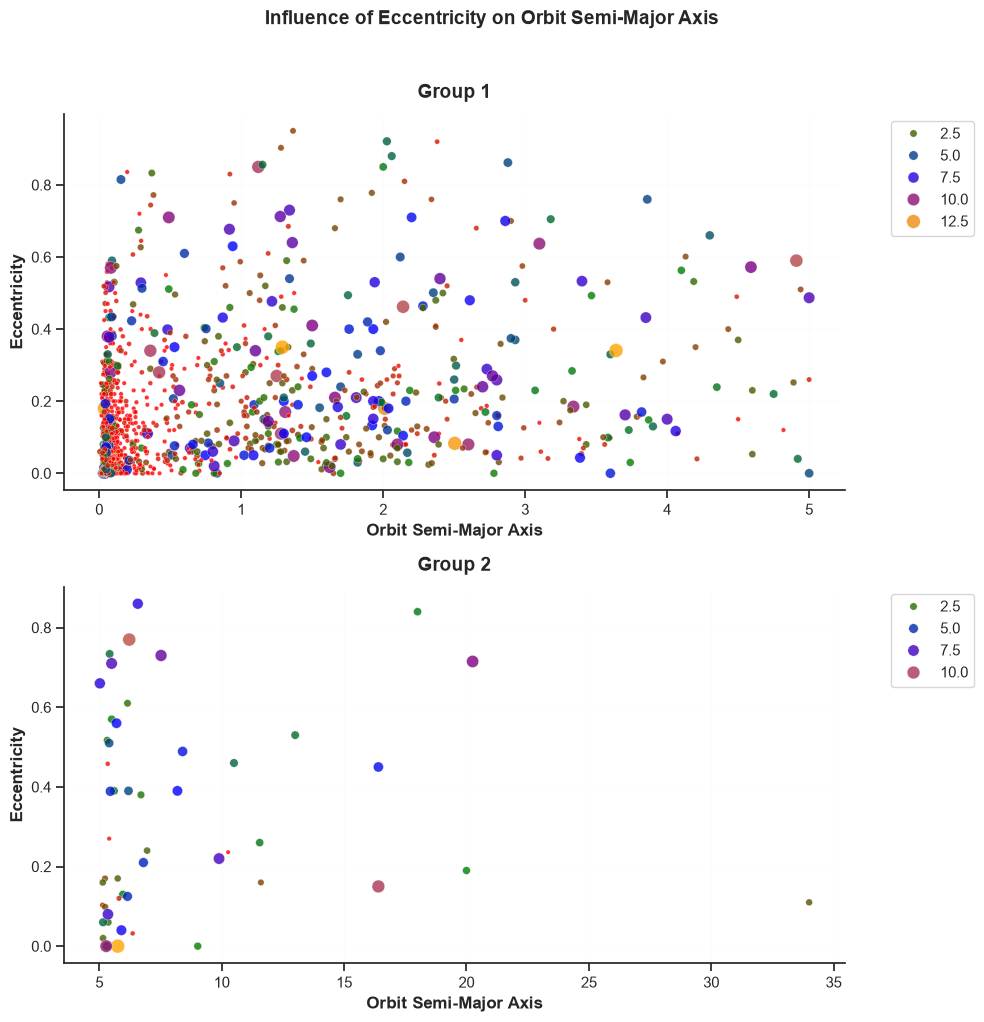

21-Oct-26 09:26:12 - __main__ - INFO - Slope: 0.03
21-Oct-26 09:26:12 - __main__ - INFO - Correlation: 0.29


In [10]:
try:
    axis_eccentricity = clean_df[["Orbit Semi-Major Axis", "Eccentricity", "Mass"]].dropna()
    axis_eccentricity["mass_jup"] = axis_eccentricity["Mass"] / 317.8 #turn earth masses to jupiter masses
    axis_eccentricity = axis_eccentricity[axis_eccentricity["mass_jup"] < 13] #planets less than jupiter masses only; bigger than that are considered brown dwarfs territory
    log.info(f"Working with {len(axis_eccentricity)} planets")
    axis_eccentricity = axis_eccentricity.copy()
    group1 = axis_eccentricity[axis_eccentricity["Orbit Semi-Major Axis"] <= 5 ]
    group2 = axis_eccentricity[axis_eccentricity["Orbit Semi-Major Axis"] > 5 ]
    log.info(f"Working with {len(group1)} planets for group 1")
    log.info(f"Working with {len(group2)} planets for group 2")
    colors = ["red", "green", "blue", "purple", "orange"]
    bounds = [2,4,6,8,10,12]
    custom_colors = LinearSegmentedColormap.from_list("Custom", colors)
    norm = BoundaryNorm(bounds, custom_colors.N)
    sns.set_theme(style="ticks")
    fig, axes = plt.subplots(2, 1, figsize=(10, 10))
    scatter = sns.scatterplot(
        x= group1["Orbit Semi-Major Axis"],
        y= group1["Eccentricity"],
        hue=group1["mass_jup"],
        size=group1["mass_jup"],
        palette=custom_colors,
        sizes=(10,100),
        alpha=0.8,
        ax= axes[0],
    )
    axes[0].set_xlabel("Orbit Semi-Major Axis", fontsize=12, fontweight="bold")
    axes[0].set_ylabel("Eccentricity", fontsize=12, fontweight="bold")
    axes[0].set_title("Group 1", fontsize=14, fontweight="bold", y=1.02)
    axes[0].grid(True, alpha=0.1, linewidth=0.4)
    axes[0].spines["top"].set_visible(False)
    axes[0].spines["right"].set_visible(False)
    axes[0].legend(bbox_to_anchor=(1.05, 1), loc = "upper left") #add a legend / label and adjust it' s position
    scatter = sns.scatterplot(
        x = group2["Orbit Semi-Major Axis"],
        y=group2["Eccentricity"],
        hue=group2["mass_jup"],
        size=group2["mass_jup"],
        palette=custom_colors,
        sizes=(10,100),
        alpha=0.8,
        ax = axes[1]
    )
    axes[1].set_xlabel("Orbit Semi-Major Axis", fontsize=12, fontweight="bold")
    axes[1].set_ylabel("Eccentricity", fontsize=12, fontweight="bold")
    axes[1].set_title("Group 2", fontsize=14, fontweight="bold", y=1.02)
    axes[1].grid(True, alpha=0.1, linewidth=0.4)
    axes[1].spines["top"].set_visible(False)
    axes[1].spines["right"].set_visible(False)
    axes[1].legend(bbox_to_anchor=(1.05, 1), loc = "upper left")
    plt.suptitle("Influence of Eccentricity on Orbit Semi-Major Axis", fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()
    slope, intercept, r_value, p_value, std_err = stats.linregress(axis_eccentricity["Orbit Semi-Major Axis"], axis_eccentricity["Eccentricity"]) #calculate the correlation and slope for the two variables
    log.info(f"Slope: {slope:.2f}")
    log.info(f"Correlation: {r_value:.2f}")
except KeyError as e:
    log.error(f"Column not found in dataframe; check column names again: {e}")
    raise
except Exception as e:
    log.error(f"An unexpected error has occurred: {e}")
    raise

The scatter plot showed no strong relationship between Eccentricity and Orbit Semi-Major axis of a planet. In the first scatter, there were planets with short orbits hence small semi major axis but high eccentric orbits and others with small eccentricity; planets with relatively bigger orbits with some having highly elliptic orbits and others almost circular orbits. In the second scatter the pattern repeated, showing no particular trend between these two variables. This meant these are independent to each other. A good example using the solar system is Earth and Mercury. Despite mercury having a shorter orbit, it ' s orbit is way more eccentric than earth' s orbit. This shows that a larger orbit does not necessarily mean higher eccentricity. Similarly, some outer planets in the solar system like Jupiter, Saturn and Uranus all have more eccentric orbits than earth, proving that some planets might have bigger orbits which are also more eccentric.
In an edge case where two planets in two different systems; system A has a planet orbiting it ' s star in an almost circular orbit and system B has a planet orbiting it ' s star with a very elliptical orbit. One might wonder what effect this could have on the semi-major axis as well as the orbital period days. The size of the orbit remains the semi despite one being more circular. The period days also remain the same. Assuming the masses of both of the stars in those systems are identical, then in system A, the planet orbits with uniform velocity throughout the orbit since the gravitational pull on the planet by the star is uniform; the planet in system B however, experiences a stronger gravitational pull at the perihelion (closest point to it ' s star)  and this makes the planet to accelerate. When it is moving towards the aphelion(farthest point from it ' s star) it expereinces weaker gravitational pull and therefore slows down. The difference between these two velocities cancel out perfectly, and therefore it's Orbital period matches that one of the planet in system A.
In conclusion, the investigation shows that Eccentricity and Semi-Major axis are independent variables to each other.

How does Stellar radius vary with stellar mass?

21-Oct-26 09:59:52 - __main__ - INFO - Mass radius column: 3331
21-Oct-26 09:59:52 - __main__ - INFO - Working with 3300 stars for group 1
21-Oct-26 09:59:52 - __main__ - INFO - Working with 31 stars for group 2


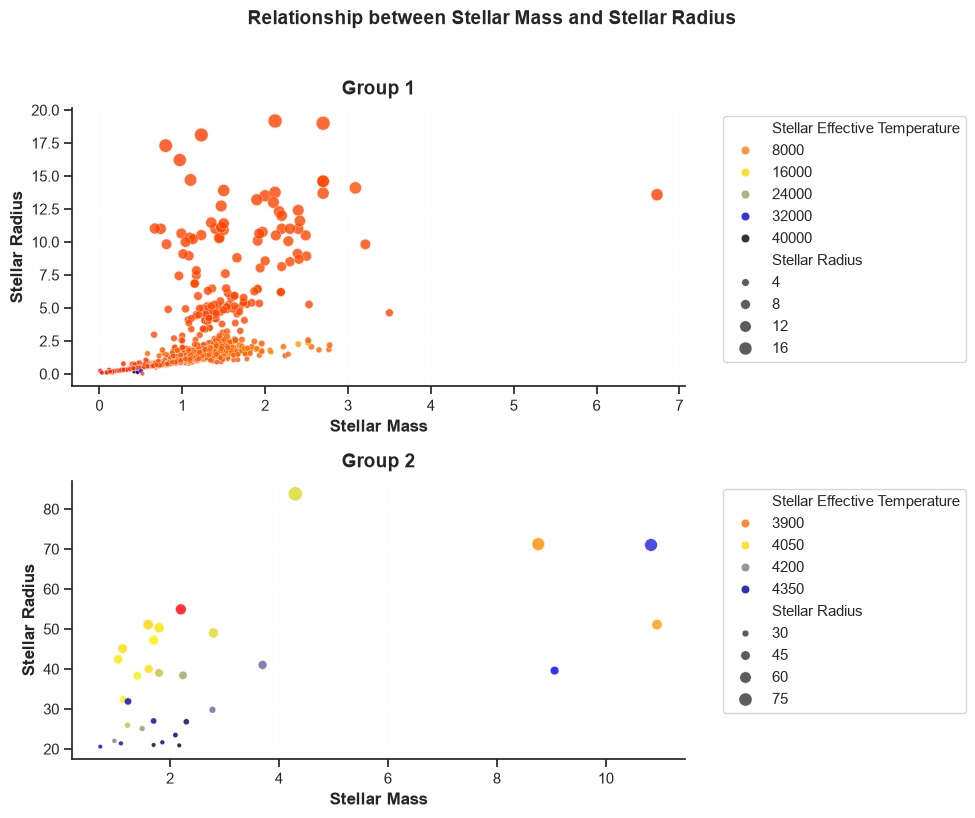

21-Oct-26 09:59:53 - __main__ - INFO - Correlation: 0.61
21-Oct-26 09:59:53 - __main__ - INFO - Slope: 5.42


In [12]:
try:
    mass_radius = clean_df[["Stellar Mass", "Stellar Radius", "Stellar Effective Temperature"]].dropna()
    log.info(f"Mass radius column: {len(mass_radius)}")
    group1 = mass_radius[mass_radius["Stellar Radius"] <= 20 ]
    group2 = mass_radius[mass_radius["Stellar Radius"] > 20 ]
    log.info(f"Working with {len(group1)} stars for group 1")
    log.info(f"Working with {len(group2)} stars for group 2")
    colors = ["red", "orange", "yellow", "blue", "black"]
    bounds = [2000,4000,6000,8000,10000,40000]
    custom_colors = LinearSegmentedColormap.from_list("Custom", colors)
    norm = BoundaryNorm(bounds, custom_colors.N)
    sns.set_theme(style="ticks")
    fig, axes = plt.subplots(2,1, figsize=(10, 8))
    scatter = sns.scatterplot(
        x = group1["Stellar Mass"],
        y = group1["Stellar Radius"],
        #data = group1,
        hue= group1["Stellar Effective Temperature"],
        size=group1["Stellar Radius"],
        palette=custom_colors,
        sizes=(10,100),
        alpha=0.8,
        ax= axes[0],
    )
    axes[0].set_xlabel("Stellar Mass", fontsize=12, fontweight="bold")
    axes[0].set_ylabel("Stellar Radius", fontsize=12, fontweight="bold")
    axes[0].set_title("Group 1", fontsize=14, fontweight="bold", y=1.02)
    axes[0].grid(True, alpha=0.1, linewidth=0.4)
    axes[0].spines["top"].set_visible(False)
    axes[0].spines["right"].set_visible(False)
    axes[0].legend(bbox_to_anchor=(1.05, 1), loc = "upper left")
    scatter_2 = sns.scatterplot(
        x = group2["Stellar Mass"],
        y =group2["Stellar Radius"],
        #data = group2,
        hue=group2["Stellar Effective Temperature"],
        size=group2["Stellar Radius"],
        palette=custom_colors,
        sizes=(10,100),
        alpha=0.8,
        ax = axes[1],
    )
    axes[1].set_xlabel("Stellar Mass", fontsize=12, fontweight="bold")
    axes[1].set_ylabel("Stellar Radius", fontsize=12, fontweight="bold")
    axes[1].set_title("Group 2", fontsize=14, fontweight="bold", y=1.02)
    axes[1].grid(True, alpha=0.1, linewidth=0.4)
    axes[1].spines["top"].set_visible(False)
    axes[1].spines["right"].set_visible(False)
    axes[1].legend(bbox_to_anchor=(1.05, 1), loc = "upper left")
    plt.suptitle("Relationship between Stellar Mass and Stellar Radius", fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()
    slope, intercept, r_value, p_value, std_err = stats.linregress(mass_radius["Stellar Mass"], mass_radius["Stellar Radius"])
    log.info(f"Correlation: {r_value:.2f}")
    log.info(f"Slope: {slope:.2f}")
except KeyError as e:
    log.error(f"Column not found, check column names again: {e}")
    raise
except Exception as e:
    log.error(f"An unexpected error has occurred: {e}")

Analysis of how stellar radius related to stellar mass showed that the both variables had a correlation of 0.61; This was a positive correlation. However, the dataset contained stars that had evolved out of the main sequence. These stars represented red super giants or Asymptotic Giant Branch; they had ran out of oxygen, their core had contracted and the outer envelope had expanded massively. An example of a star evolved out of the main sequence in the dataset was HD 81817. The star is located about 900 light years away from earth and, it demonstrates how a star can bloat without gaining a single gram of weight. It is roughly 4 solar masses, started as a relatively heavy star of the bright-blue white category in main sequence. It has a radius of approximately 83.8 solar radii, meaning it has expanded very massively. It' s effective temperature is about 4140K which is cooler than our sun hence it glows orange/red. The star shines with a luminosity of  approximately 2000 suns as it has an immense surface area hence way bigger energy output than the sun. The star is listed as relatively young roughly 150 million years old, and has evolved faster because high mass star burn hydrogen faster than low mass stars. The star is deemed a hybrid star. Usually, old cool giant stars have slow, cool stellar winds, whereas hot  active stars have intense X-ray and UV emissions. This star does both and hence the name "hybrid". The emissions are said to be caused by a white dwarf orbiting the giant. This white dwarf is said to be the dead core of what used to be the most massive star in the system.
How mass and radius interact depends entirely on the evolutionary stage of the star. During the main sequence the relationship here is a predictable, tight mathematical relationship. The radius here scales as a power law of their mass.
During the post-main sequence, the core collapses due to lack of any more fusion and therefore gravity wins. This core becomes incredibly hot and dense. Intense heat from the collapsing core will ignite a layer of hydrogen just outside the core , causing the shell to burn. This explosive new energy dumps heat into the outer layers and to dump this heat, the outer envelope balloons outwards by factors of 100x to 1000x. During this stage mass stas nearly constant or drops slightly due to stellar winds but the radius will explode massively. This destroys the mass-radius relationship.
when a star is completely dead then the radius-mass relationship gets inverted.  For stars that collapse into white dwarfs, more massive white dwarfs are physically smaller than low-mass white dwarfs hence the relationship might become a strong negative in that one increases as the other decreases. This is because adding mass increases gravity, crushing the electron-degenerate gas into a tighter, denser ball.
For stars that are more massive, they might collapse into neutron stars where mass could range from 1.4-2.1 solar masses but the radius is very small. Gravity here is held back by neutron degeneracy pressure. The radius could range from 10-12km strengthening the inverted mass-radius relationship.
For very massive stars, they collapse directly into blackholes and here the radius (event horizon) scales linearly with mass. The more the mass the bigger the physical size of the singularity's boundary.
In conclusion how mass and radius of stars relate depends entirely on the evolutionary stage of the star. In the main sequence the relationship is linear in that higher radius provides more surface area to pack matter and therefore more mass, but after exiting the main sequence, this relationship breaks.